# Sprint 2 – Notebook 14: Statistics in Machine Learning

# 1. Introduction – Statistics in Machine Learning

What is Statistics in Machine Learning?

Statistics in Machine Learning is the use of statistical methods to analyze data, understand patterns, prepare features, train models and evaluate predictions.

Statistics helps Machine Learning algorithms learn from data and make predictions.

Why is Statistics important in Machine Learning?
- Helps understand datasets.
- Helps handle missing values.
- Helps detect outliers.
- Helps transform features.
- Helps scale and normalize data.
- Helps evaluate model performance.
- Helps understand relationships between variables.
- Helps make data-driven decisions.

# Statistics vs Machine Learning

Statistics	Machine Learning

Focuses on analyzing data and drawing conclusions	Focuses on learning patterns and making predictions

Helps understand distributions, relationships and uncertainty	Uses data to learn patterns

Often focuses on inference and explanation	Often focuses on prediction and generalization

Uses methods like hypothesis testing and confidence intervals	Uses algorithms like Regression, Classification and Clustering

Example
Suppose we want to predict student exam marks using:
- Study Hours
- Attendance
- Previous Marks

Statistics helps us understand these features, clean the data, scale values, analyze relationships and evaluate the predictions.

# 2. Statistics in Data Cleaning

What is Data Cleaning?

Data Cleaning is the process of identifying and correcting or handling errors, missing values, duplicates, inconsistent data and other data quality problems.

Why is Statistics used in Data Cleaning?

Statistics helps us:
- Identify unusual values.
- Understand data distributions.
- Detect missing data patterns.
- Identify inconsistent values.
- Understand data quality.

Example
Suppose student study hours contain values such as 2, 4, 5, 6, 100 and 8.

The value 100 may be an unusual value that requires investigation.

Python Implementation

In [1]:
import pandas as pd
import numpy as np

data = {
    "Study_Hours": [2, 4, 5, 6, 100, 8],
    "Attendance": [60, 70, 75, 80, 90, 85],
    "Exam_Marks": [40, 50, 55, 60, 95, 70]
}

df = pd.DataFrame(data)

df

,Study_Hours,Attendance,Exam_Marks
0,2,60,40
1,4,70,50
2,5,75,55
3,6,80,60
4,100,90,95
5,8,85,70


Identify Basic Data Problems

In [2]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDescriptive Statistics:")
print(df.describe())

Missing Values:
Study_Hours    0
Attendance     0
Exam_Marks     0
dtype: int64

Duplicate Rows:
0

Descriptive Statistics:
       Study_Hours  Attendance  Exam_Marks
count     6.000000    6.000000    6.000000
mean     20.833333   76.666667   61.666667
std      38.835122   10.801234   19.148542
min       2.000000   60.000000   40.000000
25%       4.250000   71.250000   51.250000
50%       5.500000   77.500000   57.500000
75%       7.500000   83.750000   67.500000
max     100.000000   90.000000   95.000000


Interpretation
- isnull() identifies missing values.
- duplicated() identifies duplicate rows.
- describe() gives statistical summaries such as mean, standard deviation, minimum, maximum and quartiles.
- Statistical summaries help us identify values that may require investigation.

Important: An unusual value is not automatically an error. It should be investigated before removing or modifying it.

# 3. Statistics in Missing Value Handling

What is Missing Value Handling?

Missing Value Handling is the process of identifying and treating missing values in a dataset.

Missing values can affect Machine Learning model training and predictions.

Why is Statistics used?

Statistics helps us select suitable values to replace missing data.

Common methods:
- Mean Imputation
- Median Imputation
- Mode Imputation

Mean Imputation:

Mean imputation replaces missing values with the average value of a numerical feature.


Median Imputation:

Median imputation replaces missing values with the middle value of a sorted dataset.

Median is often useful when numerical data is skewed or contains extreme values.


Mode Imputation:

Mode imputation replaces missing values with the most frequently occurring value.

It is commonly used for categorical features.

In [3]:
data = {
    "Study_Hours": [2, 4, np.nan, 6, 8],
    "Attendance": [60, 70, 75, np.nan, 85],
    "Exam_Marks": [40, 50, 55, 60, 70]
}

df = pd.DataFrame(data)

df

,Study_Hours,Attendance,Exam_Marks
0,2.0,60.0,40
1,4.0,70.0,50
2,NaN,75.0,55
3,6.0,NaN,60
4,8.0,85.0,70


Calculate Mean and Median

In [4]:
print("Study Hours Mean:", df["Study_Hours"].mean())
print("Study Hours Median:", df["Study_Hours"].median())

Study Hours Mean: 5.0
Study Hours Median: 5.0


Fill Missing Values

In [5]:
df["Study_Hours"] = df["Study_Hours"].fillna(
    df["Study_Hours"].mean()
)

df["Attendance"] = df["Attendance"].fillna(
    df["Attendance"].median()
)

df

,Study_Hours,Attendance,Exam_Marks
0,2.0,60.0,40
1,4.0,70.0,50
2,5.0,75.0,55
3,6.0,72.5,60
4,8.0,85.0,70


# 4. Statistics in Outlier Detection

What is Outlier Detection?

Outlier Detection is the process of identifying data points that are unusually different from the other observations.

Statistics helps detect outliers using methods such as:
- IQR Method
- Z-Score Method

In [6]:
marks = pd.Series([40, 45, 50, 55, 60, 65, 70, 75, 100, 200])

Q1 = marks.quantile(0.25)
Q3 = marks.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = marks[
    (marks < lower_bound) | (marks > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Outliers:")
print(outliers)

Q1: 51.25
Q3: 73.75
IQR: 22.5
Lower Bound: 17.5
Upper Bound: 107.5
Outliers:
9    200
dtype: int64


Interpretation
- Q1 represents the 25th percentile.
- Q3 represents the 75th percentile.
- IQR measures the spread of the middle 50% of the data.
- Values outside the IQR boundaries are flagged as potential outliers.

Visualize Outliers

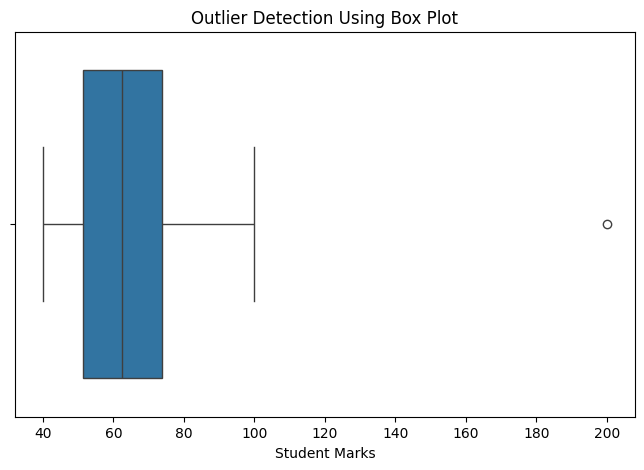

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(x=marks)

plt.title("Outlier Detection Using Box Plot")
plt.xlabel("Student Marks")

plt.show()

# 5. Statistics in Feature Engineering

What is Feature Engineering?

Feature Engineering is the process of creating, transforming or selecting features to make data more useful for Machine Learning models.

Statistics helps us create meaningful features from existing data.

Why is Statistics used?
- To understand feature distributions.
- To transform features.
- To create new features.
- To identify useful variables.
- To improve the quality of input data.

Example
Suppose we have:
- Study Hours
- Attendance
- Previous Marks

We can create a new feature called Study_Efficiency to represent the ratio of study hours to attendance, but its meaning and usefulness should be justified carefully.

For a simpler practical feature, we will create Total_Study_Hours_Weekly by multiplying average daily study hours by 7.

Python Implementation

In [8]:
df = pd.DataFrame({
    "Daily_Study_Hours": [2, 3, 4, 5, 6],
    "Attendance": [60, 70, 80, 85, 90],
    "Previous_Marks": [45, 50, 60, 70, 80]
})

df["Weekly_Study_Hours"] = (
    df["Daily_Study_Hours"] * 7
)

df

,Daily_Study_Hours,Attendance,Previous_Marks,Weekly_Study_Hours
0,2,60,45,14
1,3,70,50,21
2,4,80,60,28
3,5,85,70,35
4,6,90,80,42


# 6. Statistics in Feature Scaling

What is Feature Scaling?

Feature Scaling is the process of adjusting the numerical range or scale of features so that they can be used more effectively by certain Machine Learning algorithms.

Why is Feature Scaling important?

Features may have different scales.

For example:
- Study Hours: 1 to 10
- Attendance: 0 to 100
- Previous Marks: 0 to 100

Some algorithms are sensitive to feature scales.

Feature scaling is particularly useful for algorithms such as:
- K-Nearest Neighbors (KNN)
- Support Vector Machine (SVM)
- Logistic Regression
- Gradient-based optimization methods
- Neural Networks

In [9]:
from sklearn.preprocessing import StandardScaler

data = pd.DataFrame({
    "Study_Hours": [2, 4, 6, 8, 10],
    "Attendance": [50, 60, 70, 80, 90],
    "Previous_Marks": [40, 50, 60, 70, 80]
})

scaler = StandardScaler()

scaled_data = scaler.fit_transform(data)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=data.columns
)

scaled_df

,Study_Hours,Attendance,Previous_Marks
0,-1.414214,-1.414214,-1.414214
1,-0.707107,-0.707107,-0.707107
2,0.000000,0.000000,0.000000
3,0.707107,0.707107,0.707107
4,1.414214,1.414214,1.414214


# 7. Statistics in Data Normalization

What is Data Normalization?

Data Normalization is a feature transformation that scales values to a specified range.

A commonly used normalization method is Min-Max Scaling.

Why is Normalization important?
- Makes features comparable.
- Helps algorithms that depend on distances.
- Useful for certain optimization methods.
- Prevents features with larger numerical scales from dominating some calculations.

Python Implementation

In [10]:
from sklearn.preprocessing import MinMaxScaler

data = pd.DataFrame({
    "Study_Hours": [2, 4, 6, 8, 10],
    "Attendance": [50, 60, 70, 80, 90],
    "Previous_Marks": [40, 50, 60, 70, 80]
})

scaler = MinMaxScaler()

normalized_data = scaler.fit_transform(data)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=data.columns
)

normalized_df

,Study_Hours,Attendance,Previous_Marks
0,0.00,0.00,0.00
1,0.25,0.25,0.25
2,0.50,0.50,0.50
3,0.75,0.75,0.75
4,1.00,1.00,1.00


# 8. Statistics in Model Evaluation

What is Model Evaluation?

Model Evaluation is the process of measuring how well a Machine Learning model performs on data.

Statistics helps us understand model performance, prediction errors and the reliability of evaluation results.

Why is Statistics used?
- Measures model performance.
- Helps compare models.
- Analyzes prediction errors.
- Helps understand performance variation.
- Supports model selection.

# Common Regression Metrics

Metric	Description

MAE	Mean Absolute Error

MSE	Mean Squared Error

RMSE  Root Mean Squared Error

R²	Proportion of target variance explained by the model

In [11]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

actual = [40, 50, 60, 70, 80]
predicted = [42, 48, 58, 72, 78]

mae = mean_absolute_error(actual, predicted)
mse = mean_squared_error(actual, predicted)
rmse = np.sqrt(mse)
r2 = r2_score(actual, predicted)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 2.0
MSE: 4.0
RMSE: 2.0
R2 Score: 0.98


# 9. Statistics in Linear Regression

What is Linear Regression?

Linear Regression is a Machine Learning algorithm used to predict a numerical value based on one or more input features.

It models a relationship between independent variables and a dependent variable.
Formula

Example

We want to predict student exam marks based on study hours.

Python Implementation

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

data = pd.DataFrame({
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8],
    "Exam_Marks": [35, 40, 45, 50, 55, 60, 70, 80]
})

X = data[["Study_Hours"]]
y = data["Exam_Marks"]

model = LinearRegression()

model.fit(X, y)

predictions = model.predict(X)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Coefficient: 6.130952380952383
Intercept: 26.785714285714278


Visualize Linear Regression

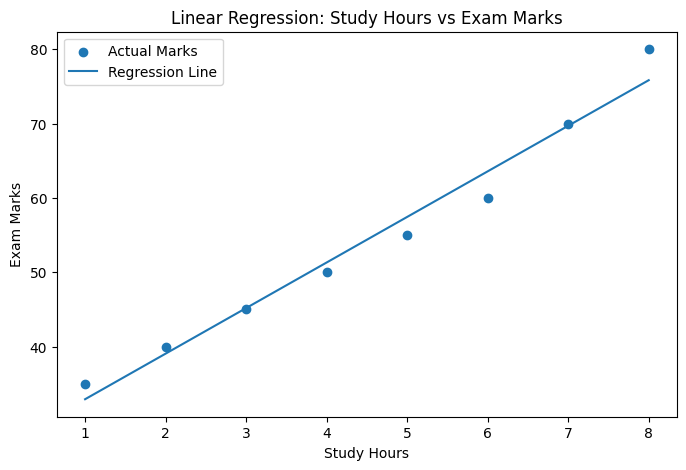

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(
    data["Study_Hours"],
    data["Exam_Marks"],
    label="Actual Marks"
)

plt.plot(
    data["Study_Hours"],
    predictions,
    label="Regression Line"
)

plt.xlabel("Study Hours")
plt.ylabel("Exam Marks")
plt.title("Linear Regression: Study Hours vs Exam Marks")

plt.legend()
plt.show()

# 10. Statistics in Logistic Regression

What is Logistic Regression?

Logistic Regression is a Machine Learning algorithm used primarily for classification problems.

It estimates the probability of an observation belonging to a particular class.

Despite its name, Logistic Regression is a classification algorithm.

Example

Suppose we want to predict whether a student will pass based on study hours.

Python Implementation

In [14]:
import pandas as pd

from sklearn.linear_model import LogisticRegression

data = pd.DataFrame({
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Pass": [0, 0, 0, 0, 1, 1, 1, 1, 1, 1]
})

X = data[["Study_Hours"]]
y = data["Pass"]

model = LogisticRegression()

model.fit(X, y)

probabilities = model.predict_proba(X)

print("Pass Probabilities:")
print(probabilities[:, 1])

Pass Probabilities:
[0.0158326  0.04984175 0.14606217 0.35804107 0.64521527 0.85569961
 0.95082626 0.98438709 0.99515943 0.99851049]


Example Prediction

In [15]:
new_student = pd.DataFrame({
    "Study_Hours": [5]
})

probability = model.predict_proba(new_student)[0, 1]

print("Probability of Passing:", probability)

Probability of Passing: 0.6452152711460055


# 11. Statistics in Naive Bayes

What is Naive Bayes?

Naive Bayes is a Machine Learning classification algorithm based on Bayes' Theorem.

It assumes that features are conditionally independent given the class, which is a simplifying assumption.

Example

We want to predict whether a student will pass based on study hours.

Python Implementation

In [16]:
import pandas as pd

from sklearn.naive_bayes import GaussianNB

data = pd.DataFrame({
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Pass": [0, 0, 0, 0, 1, 1, 1, 1, 1, 1]
})

X = data[["Study_Hours"]]
y = data["Pass"]

model = GaussianNB()

model.fit(X, y)

predictions = model.predict(X)

print("Predictions:")
print(predictions)

Predictions:
[0 0 0 0 1 1 1 1 1 1]


# 12. Statistics in Clustering

What is Clustering?

Clustering is an unsupervised Machine Learning technique used to group similar observations together without predefined labels.

How is Statistics used?

Statistics helps Clustering:
- Analyze data distributions.
- Calculate distances.
- Understand cluster characteristics.
- Identify group patterns.
- Evaluate clustering results.

Example

Suppose we want to group students based on study hours and exam marks.

Students with similar study habits and marks may belong to the same cluster.

Python Implementation

In [17]:
import pandas as pd

from sklearn.cluster import KMeans

data = pd.DataFrame({
    "Study_Hours": [1, 2, 3, 4, 7, 8, 9, 10],
    "Exam_Marks": [30, 35, 40, 45, 70, 75, 80, 90]
})

X = data[["Study_Hours", "Exam_Marks"]]

model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

data["Cluster"] = model.fit_predict(X)

data

,Study_Hours,Exam_Marks,Cluster
0,1,30,0
1,2,35,0
2,3,40,0
3,4,45,0
4,7,70,1
5,8,75,1
6,9,80,1
7,10,90,1


Visualize Clusters

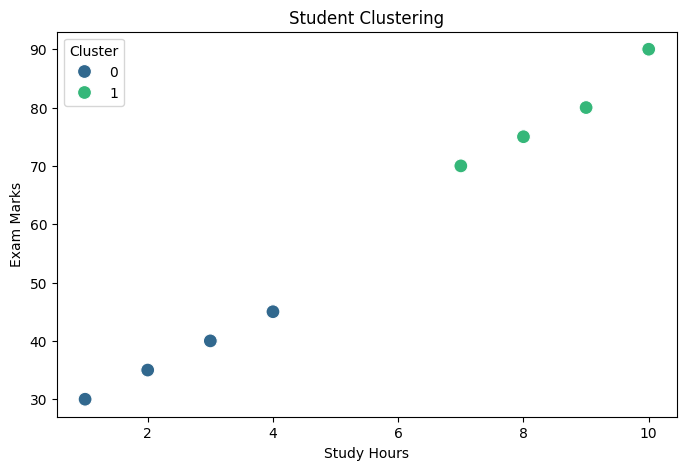

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x="Study_Hours",
    y="Exam_Marks",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.title("Student Clustering")
plt.xlabel("Study Hours")
plt.ylabel("Exam Marks")

plt.show()

# 13. Statistics in Principal Component Analysis (PCA)

What is PCA?

Principal Component Analysis (PCA) is a dimensionality reduction technique used to transform a dataset into a smaller number of features while preserving as much variance as possible.

Why is PCA important?
- Reduces the number of features.
- Helps visualize high-dimensional data.
- Can reduce redundancy.
- Can reduce computational complexity.
- Helps identify major patterns in data.

How is Statistics used?

PCA uses statistical concepts such as:
- Variance.
- Covariance.
- Eigenvalues.
- Eigenvectors.
- Linear transformations.

How PCA works
1. Standardize features when appropriate.
2. Calculate the covariance structure of the data.
3. Identify principal component directions.
4. Rank components based on explained variance.
5. Transform the data into the selected components.

Python Implementation

In [19]:
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

data = pd.DataFrame({
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8],
    "Attendance": [50, 55, 60, 65, 70, 75, 80, 85],
    "Previous_Marks": [30, 35, 40, 45, 50, 55, 60, 65]
})

scaler = StandardScaler()

scaled_data = scaler.fit_transform(data)

pca = PCA(n_components=2)

transformed_data = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(
    transformed_data,
    columns=["PC1", "PC2"]
)

pca_df

,PC1,PC2
0,-2.645751,-4.266186e-16
1,-1.889822,2.557369e-16
2,-1.133893,2.653306e-17
3,-0.377964,2.395257e-17
4,0.377964,-2.395257e-17
5,1.133893,-2.653306e-17
6,1.889822,-2.557369e-16
7,2.645751,-3.169402e-17


Explained Variance

In [20]:
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Explained:")
print(pca.explained_variance_ratio_.sum())

Explained Variance Ratio:
[1.00000000e+00 1.31819205e-32]

Total Variance Explained:
1.0


Visualize PCA

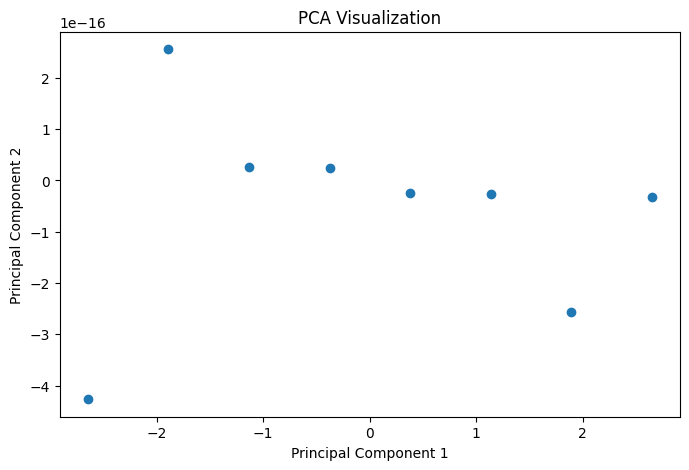

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"]
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization")

plt.show()

# 4. Statistics in Recommendation Systems

What is a Recommendation System?

A Recommendation System is a Machine Learning or data-driven system that suggests products, movies, courses or other items based on user preferences, behavior or similarities.

Why is Statistics used?
Statistics helps Recommendation Systems:
- Analyze user preferences.
- Calculate averages and ratings.
- Measure similarity.
- Analyze frequency of interactions.
- Identify patterns.
- Estimate recommendation scores.

Example
Suppose students rate different online courses.

We can calculate average course ratings and recommend courses with higher average ratings, while recognizing that simple averages may not be sufficient.

Python Implementation

In [22]:
import pandas as pd

data = pd.DataFrame({
    "Student": ["A", "A", "B", "B", "C", "C", "D", "D"],
    "Course": [
        "Python", "SQL",
        "Python", "Data Science",
        "SQL", "Data Science",
        "Python", "SQL"
    ],
    "Rating": [5, 4, 4, 5, 5, 4, 5, 3]
})

data

,Student,Course,Rating
0,A,Python,5
1,A,SQL,4
2,B,Python,4
3,B,Data Science,5
4,C,SQL,5
5,C,Data Science,4
6,D,Python,5
7,D,SQL,3


Calculate Average Course Ratings

In [23]:
average_ratings = data.groupby(
    "Course"
)["Rating"].mean().sort_values(ascending=False)

print(average_ratings)

Course
Python          4.666667
Data Science    4.500000
SQL             4.000000
Name: Rating, dtype: float64


Visualize Average Ratings

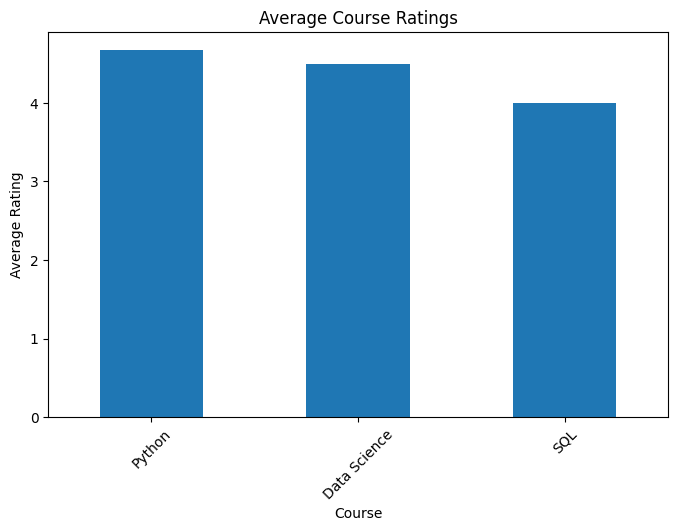

In [24]:
plt.figure(figsize=(8, 5))

average_ratings.plot(kind="bar")

plt.title("Average Course Ratings")
plt.xlabel("Course")
plt.ylabel("Average Rating")

plt.xticks(rotation=45)

plt.show()

# 16. Advantages of Statistics in Machine Learning
1. Helps understand data.
2. Helps identify data quality problems.
3. Helps handle missing values.
4. Helps detect outliers.
5. Helps prepare features.
6. Helps evaluate models.
7. Helps understand relationships between variables.
8. Helps improve decision-making.

# 17. Limitations of Statistics in Machine Learning
1. Statistical methods depend on assumptions.
2. Incorrect statistical interpretation can lead to misleading conclusions.
3. Data quality affects statistical results.
4. Statistical analysis alone does not guarantee a good Machine Learning model.
5. Correlation does not imply causation.
6. Statistical significance does not always mean practical significance.